In [3]:
import pandas as pd

In [4]:
from google.colab import files

archivo_subido = files.upload()

Saving ds_24406_1.csv to ds_24406_1.csv


In [5]:
import pandas as pd

nombre_archivo = list(archivo_subido.keys())[0]

df = pd.read_csv(nombre_archivo)

print("¡Archivo cargado correctamente!")

¡Archivo cargado correctamente!


In [12]:
df.head()

,Trimestre,Tipo de producto,Corredor,Empresa,Tipo de servicio,Ingresos por venta de billetes (€),Plazas Ofertadas (Núm),Plazas.km Ofertadas (Plazas.km),Tren.km (Tren.km),Viajeros (Núm),Viajeros.km (Viajeros.km)
0,2016T1,Cercanías,Total,Total,OSP,NaN,NaN,5.836879e+09,16638744.0,100892888.0,1.924136e+09
1,2016T1,LD AV,Madrid-Alicante,Renfe Viajeros,Comercial,NaN,NaN,1.857033e+08,587646.0,355281.0,1.356036e+08
2,2016T1,LD AV,Madrid-Barcelona,Renfe Viajeros,Comercial,NaN,NaN,1.229535e+09,3060141.0,1826917.0,8.523592e+08
3,2016T1,LD AV,Madrid-Málaga/Granada,Renfe Viajeros,Comercial,NaN,NaN,3.626520e+08,1009358.0,538725.0,2.478756e+08
4,2016T1,LD AV,Madrid-Sevilla,Renfe Viajeros,Comercial,NaN,NaN,4.446413e+08,1318513.0,785860.0,3.330029e+08


In [11]:
df.shape

(722, 11)

In [9]:
df = pd.read_csv(nombre_archivo, sep=";")

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 722 entries, 0 to 721
Data columns (total 11 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Trimestre                           722 non-null    object 
 1   Tipo de producto                    722 non-null    object 
 2   Corredor                            722 non-null    object 
 3   Empresa                             722 non-null    object 
 4   Tipo de servicio                    722 non-null    object 
 5   Ingresos por venta de billetes (€)  340 non-null    float64
 6   Plazas Ofertadas (Núm)              472 non-null    float64
 7   Plazas.km Ofertadas (Plazas.km)     552 non-null    float64
 8   Tren.km (Tren.km)                   552 non-null    float64
 9   Viajeros (Núm)                      552 non-null    float64
 10  Viajeros.km (Viajeros.km)           552 non-null    float64
dtypes: float64(6), object(5)
memory usage: 62.2+ 

In [13]:
df.columns.tolist()

['Trimestre',
 'Tipo de producto',
 'Corredor',
 'Empresa',
 'Tipo de servicio',
 'Ingresos por venta de billetes (€)',
 'Plazas Ofertadas (Núm)',
 'Plazas.km Ofertadas (Plazas.km)',
 'Tren.km (Tren.km)',
 'Viajeros (Núm)',
 'Viajeros.km (Viajeros.km)']

In [15]:
df["Tipo de servicio"].unique()

array(['OSP', 'Comercial'], dtype=object)

In [16]:
df["Tipo de producto"].unique()

array(['Cercanías', 'LD AV', 'LD Convencional', 'MD AV',
       'MD Convencional'], dtype=object)

In [17]:
df["Empresa"].unique()

array(['Total', 'Renfe Viajeros', 'OUIGO', 'Iryo'], dtype=object)

In [18]:
df["Tipo de servicio"].value_counts()

,count
Tipo de servicio,
Comercial,596
OSP,126


In [19]:
df.isna().sum()

,0
Trimestre,0
Tipo de producto,0
Corredor,0
Empresa,0
Tipo de servicio,0
Ingresos por venta de billetes (€),382
Plazas Ofertadas (Núm),250
Plazas.km Ofertadas (Plazas.km),170
Tren.km (Tren.km),170
Viajeros (Núm),170


In [20]:
df.duplicated().sum()

np.int64(0)

In [21]:
df.dtypes

,0
Trimestre,object
Tipo de producto,object
Corredor,object
Empresa,object
Tipo de servicio,object
Ingresos por venta de billetes (€),float64
Plazas Ofertadas (Núm),float64
Plazas.km Ofertadas (Plazas.km),float64
Tren.km (Tren.km),float64
Viajeros (Núm),float64


In [22]:
# Comprobar los valores ausentes por tipo de servicio
df.groupby("Tipo de servicio").agg({
    "Viajeros (Núm)": lambda x: x.isna().sum(),
    "Plazas Ofertadas (Núm)": lambda x: x.isna().sum(),
    "Ingresos por venta de billetes (€)": lambda x: x.isna().sum()
})

,Viajeros (Núm),Plazas Ofertadas (Núm),Ingresos por venta de billetes (€)
Tipo de servicio,,,
Comercial,170,226,358
OSP,0,24,24


In [23]:
print("Primeros trimestres:")
print(df["Trimestre"].unique()[:10])

print("\nNúmero de trimestres diferentes:")
print(df["Trimestre"].nunique())

Primeros trimestres:
['2016T1' '2016T2' '2016T3' '2016T4' '2017T1' '2017T2' '2017T3' '2017T4'
 '2018T1' '2018T2']

Número de trimestres diferentes:
42


In [24]:
# Filtrar las filas donde no conocemos el número de viajeros
sin_viajeros = df[df["Viajeros (Núm)"].isna()]

# Contar los casos por producto y empresa
tabla_ausentes = sin_viajeros.groupby(
    ["Tipo de producto", "Empresa"]
).size().unstack(fill_value=0)

tabla_ausentes

Empresa,Total
Tipo de producto,
LD AV,170


In [25]:
print("Primer trimestre:", df["Trimestre"].unique()[0])
print("Último trimestre:", df["Trimestre"].unique()[-1])

print("\nÚltimos 10 trimestres:")
print(df["Trimestre"].unique()[-10:])

Primer trimestre: 2016T1
Último trimestre: 2026T2

Últimos 10 trimestres:
['2024T1' '2024T2' '2024T3' '2024T4' '2025T1' '2025T2' '2025T3' '2025T4'
 '2026T1' '2026T2']


In [26]:
sin_viajeros[
    ["Trimestre", "Tipo de producto", "Corredor",
     "Empresa", "Tipo de servicio"]
].head(10)

,Trimestre,Tipo de producto,Corredor,Empresa,Tipo de servicio
82,2018T1,LD AV,Madrid-Alicante,Total,Comercial
84,2018T1,LD AV,Madrid-Barcelona,Total,Comercial
86,2018T1,LD AV,Madrid-Málaga/Granada,Total,Comercial
88,2018T1,LD AV,Madrid-Sevilla,Total,Comercial
90,2018T1,LD AV,Madrid-Valencia,Total,Comercial
97,2018T2,LD AV,Madrid-Alicante,Total,Comercial
99,2018T2,LD AV,Madrid-Barcelona,Total,Comercial
101,2018T2,LD AV,Madrid-Málaga/Granada,Total,Comercial
103,2018T2,LD AV,Madrid-Sevilla,Total,Comercial
105,2018T2,LD AV,Madrid-Valencia,Total,Comercial


In [27]:
# Crear una copia de los datos originales
df_analisis = df.copy()

# Contar registros con y sin datos de viajeros
print("Registros totales:", len(df_analisis))

print(
    "Registros con viajeros:",
    df_analisis["Viajeros (Núm)"].notna().sum()
)

print(
    "Registros sin viajeros:",
    df_analisis["Viajeros (Núm)"].isna().sum()
)

Registros totales: 722
Registros con viajeros: 552
Registros sin viajeros: 170


In [28]:
# Contar registros con datos de viajeros por producto
df_analisis.groupby("Tipo de producto").agg(
    registros=("Viajeros (Núm)", "size"),
    con_datos=("Viajeros (Núm)", "count"),
    sin_datos=("Viajeros (Núm)", lambda x: x.isna().sum())
)

,registros,con_datos,sin_datos
Tipo de producto,,,
Cercanías,42,42,0
LD AV,554,384,170
LD Convencional,42,42,0
MD AV,42,42,0
MD Convencional,42,42,0


In [29]:
# Comprobar el formato de los trimestres
print(df_analisis["Trimestre"].head(12).tolist())

['2016T1', '2016T1', '2016T1', '2016T1', '2016T1', '2016T1', '2016T1', '2016T1', '2016T1', '2016T1', '2016T2', '2016T2']


In [30]:
tabla_empresas = df_analisis.groupby(
    ["Tipo de producto", "Empresa"]
).size().unstack(fill_value=0)

tabla_empresas

Empresa,Iryo,OUIGO,Renfe Viajeros,Total
Tipo de producto,,,,
Cercanías,0,0,0,42
LD AV,71,61,210,212
LD Convencional,0,0,0,42
MD AV,0,0,0,42
MD Convencional,0,0,0,42


In [31]:
df_analisis[
    df_analisis["Empresa"] == "Total"
].groupby("Tipo de producto").size()

,0
Tipo de producto,
Cercanías,42
LD AV,212
LD Convencional,42
MD AV,42
MD Convencional,42


In [32]:
# Mostrar registros de LD AV con datos de viajeros
ld_av_con_datos = df_analisis[
    (df_analisis["Tipo de producto"] == "LD AV") &
    (df_analisis["Viajeros (Núm)"].notna())
]

print("Número de registros:", len(ld_av_con_datos))

display(
    ld_av_con_datos[
        ["Trimestre", "Corredor", "Empresa", "Viajeros (Núm)"]
    ].head(20)
)

Número de registros: 384


,Trimestre,Corredor,Empresa,Viajeros (Núm)
1,2016T1,Madrid-Alicante,Renfe Viajeros,355281.0
2,2016T1,Madrid-Barcelona,Renfe Viajeros,1826917.0
3,2016T1,Madrid-Málaga/Granada,Renfe Viajeros,538725.0
4,2016T1,Madrid-Sevilla,Renfe Viajeros,785860.0
5,2016T1,Madrid-Valencia,Renfe Viajeros,563933.0
6,2016T1,Resto,Total,647074.0
11,2016T2,Madrid-Alicante,Renfe Viajeros,399042.0
12,2016T2,Madrid-Barcelona,Renfe Viajeros,2084953.0
13,2016T2,Madrid-Málaga/Granada,Renfe Viajeros,631520.0
14,2016T2,Madrid-Sevilla,Renfe Viajeros,904058.0


In [33]:
# Contar registros por trimestre y empresa
ld_av_con_datos.groupby(
    ["Trimestre", "Empresa"]
).size().unstack(fill_value=0).head(10)

Empresa,Iryo,OUIGO,Renfe Viajeros,Total
Trimestre,,,,
2016T1,0,0,5,1
2016T2,0,0,5,1
2016T3,0,0,5,1
2016T4,0,0,5,1
2017T1,0,0,5,1
2017T2,0,0,5,1
2017T3,0,0,5,1
2017T4,0,0,5,1
2018T1,0,0,5,1


In [34]:
# Comprobar los corredores registrados para cada empresa en LD AV

ld_av = df_analisis[
    df_analisis["Tipo de producto"] == "LD AV"
]

tabla_corredores = ld_av.groupby(
    ["Empresa", "Corredor"]
).size().unstack(fill_value=0)

display(tabla_corredores)

Corredor,Madrid-Alicante,Madrid-Barcelona,Madrid-Málaga/Granada,Madrid-Sevilla,Madrid-Valencia,Resto
Empresa,,,,,,
Iryo,13,15,14,14,15,0
OUIGO,13,21,6,6,15,0
Renfe Viajeros,42,42,42,42,42,0
Total,34,34,34,34,34,42


In [35]:
# Seleccionar algunos trimestres para comparar
trimestres_ejemplo = ["2016T1", "2019T1", "2022T1", "2024T1", "2026T2"]

ejemplo = ld_av[
    ld_av["Trimestre"].isin(trimestres_ejemplo)
]

display(
    ejemplo[
        ["Trimestre", "Corredor", "Empresa", "Viajeros (Núm)"]
    ].sort_values(["Trimestre", "Corredor", "Empresa"])
)

,Trimestre,Corredor,Empresa,Viajeros (Núm)
1,2016T1,Madrid-Alicante,Renfe Viajeros,355281.0
2,2016T1,Madrid-Barcelona,Renfe Viajeros,1826917.0
3,2016T1,Madrid-Málaga/Granada,Renfe Viajeros,538725.0
4,2016T1,Madrid-Sevilla,Renfe Viajeros,785860.0
5,2016T1,Madrid-Valencia,Renfe Viajeros,563933.0
...,...,...,...,...
714,2026T2,Madrid-Valencia,Iryo,386083.0
715,2026T2,Madrid-Valencia,OUIGO,334919.0
716,2026T2,Madrid-Valencia,Renfe Viajeros,834054.0
717,2026T2,Madrid-Valencia,Total,NaN


In [36]:
comprobacion = ld_av.groupby(
    ["Trimestre", "Corredor"]
).size()

print("Combinaciones con más de una fila:")
display(comprobacion[comprobacion > 1].head(20))

print(
    "Número de combinaciones con más de una fila:",
    (comprobacion > 1).sum()
)

Combinaciones con más de una fila:


Trimestre  Corredor             
2018T1     Madrid-Alicante          2
           Madrid-Barcelona         2
           Madrid-Málaga/Granada    2
           Madrid-Sevilla           2
           Madrid-Valencia          2
2018T2     Madrid-Alicante          2
           Madrid-Barcelona         2
           Madrid-Málaga/Granada    2
           Madrid-Sevilla           2
           Madrid-Valencia          2
2018T3     Madrid-Alicante          2
           Madrid-Barcelona         2
           Madrid-Málaga/Granada    2
           Madrid-Sevilla           2
           Madrid-Valencia          2
2018T4     Madrid-Alicante          2
           Madrid-Barcelona         2
           Madrid-Málaga/Granada    2
           Madrid-Sevilla           2
           Madrid-Valencia          2
dtype: int64

Número de combinaciones con más de una fila: 170


In [37]:
# 1. Crear una copia con los registros que tienen viajeros
df_viajeros = df_analisis[
    df_analisis["Viajeros (Núm)"].notna()
].copy()

# 2. Agrupar por trimestre y tipo de producto
viajeros_trimestre = df_viajeros.groupby(
    ["Trimestre", "Tipo de producto"]
)["Viajeros (Núm)"].sum().reset_index()

# 3. Cambiar el nombre de la columna
viajeros_trimestre = viajeros_trimestre.rename(
    columns={"Viajeros (Núm)": "Viajeros"}
)

# 4. Mostrar las primeras filas
display(viajeros_trimestre.head(15))

,Trimestre,Tipo de producto,Viajeros
0,2016T1,Cercanías,100892888.0
1,2016T1,LD AV,4717790.0
2,2016T1,LD Convencional,2572312.0
3,2016T1,MD AV,1752984.0
4,2016T1,MD Convencional,5443411.0
5,2016T2,Cercanías,106825480.0
6,2016T2,LD AV,5407605.0
7,2016T2,LD Convencional,2820442.0
8,2016T2,MD AV,1940205.0
9,2016T2,MD Convencional,6094877.0


In [38]:
# Contar cuántos trimestres tenemos por producto
viajeros_trimestre.groupby(
    "Tipo de producto"
)["Trimestre"].nunique()

,Trimestre
Tipo de producto,
Cercanías,42
LD AV,42
LD Convencional,42
MD AV,42
MD Convencional,42


In [39]:
# Comprobar si hay algún valor ausente en la nueva tabla
print("Valores ausentes:")
print(viajeros_trimestre.isna().sum())

# Comprobar el número total de filas
print("\nNúmero de filas:", len(viajeros_trimestre))

Valores ausentes:
Trimestre           0
Tipo de producto    0
Viajeros            0
dtype: int64

Número de filas: 210


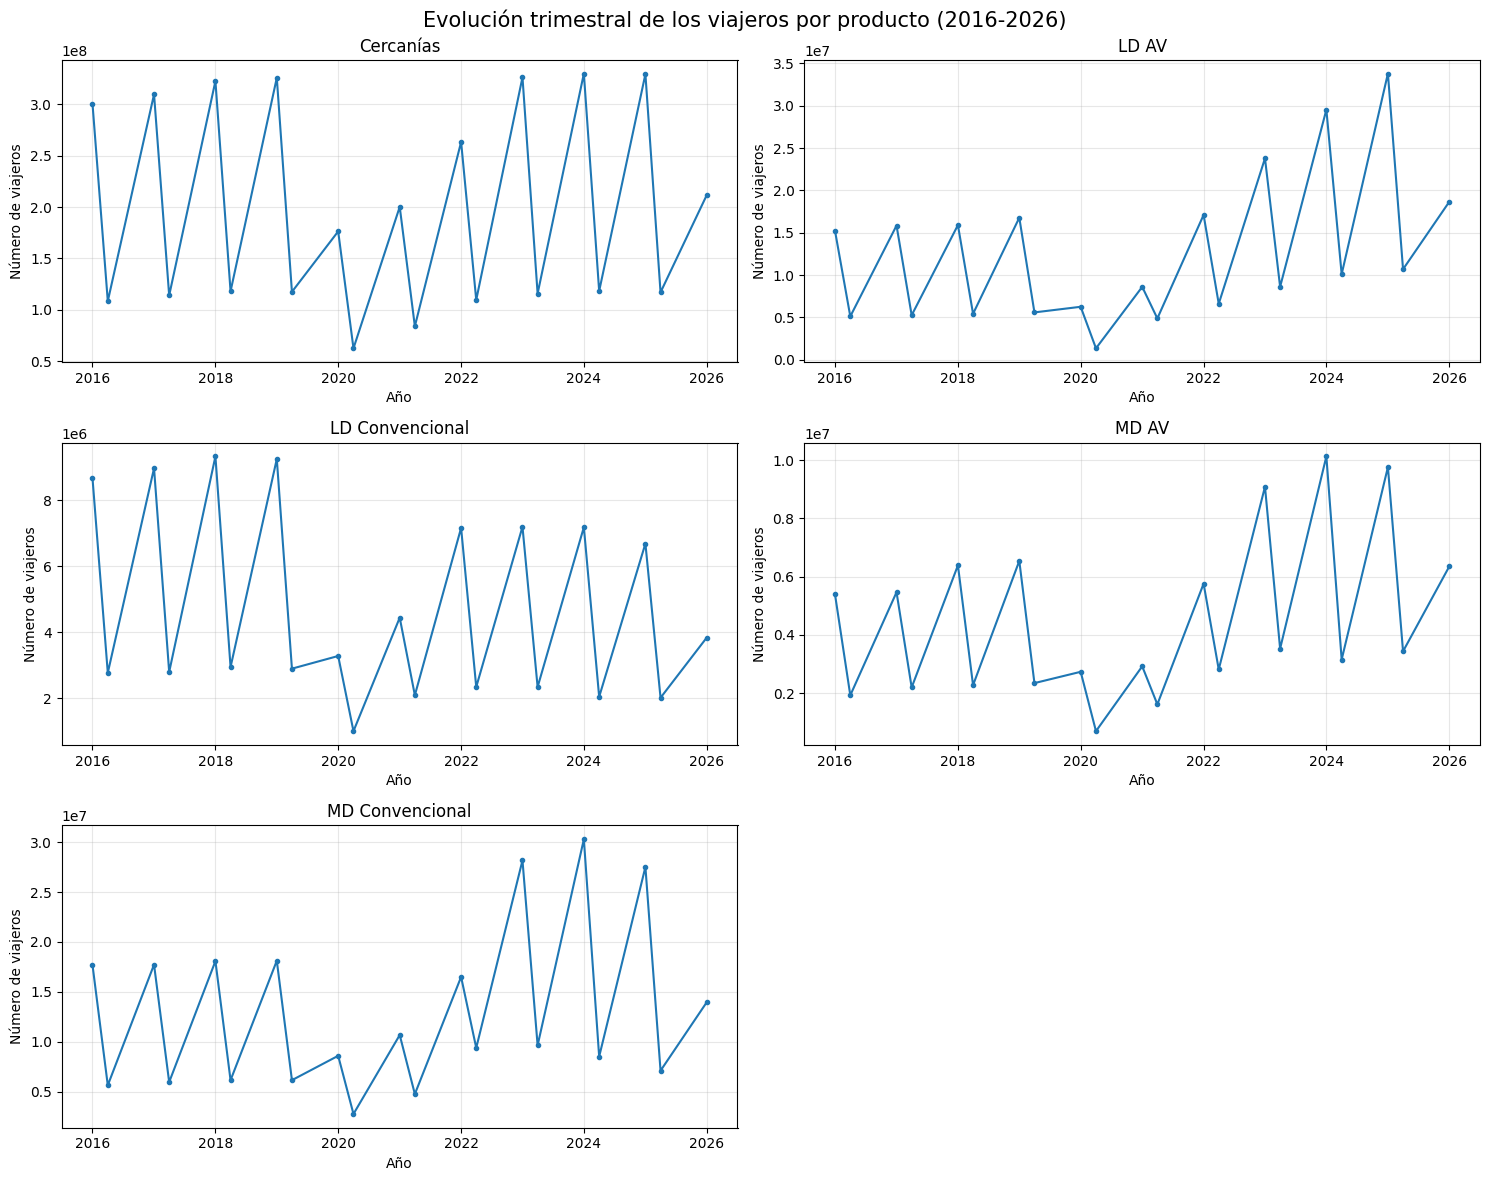

In [45]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Convertir el trimestre en una fecha que Python pueda ordenar
viajeros_trimestre["Fecha"] = pd.PeriodIndex(
    viajeros_trimestre["Trimestre"],
    freq="Q"
).to_timestamp()

# Crear una tabla con un producto por columna
tabla_grafico = viajeros_trimestre.pivot(
    index="Fecha",
    columns="Tipo de producto",
    values="Viajeros"
)

# Crear cinco gráficos
fig, axes = plt.subplots(3, 2, figsize=(15, 12))

axes = axes.flatten()

for i, producto in enumerate(tabla_grafico.columns):

    axes[i].plot(
        tabla_grafico.index,
        tabla_grafico[producto],
        marker="o",
        markersize=3
    )

    axes[i].set_title(producto)
    axes[i].set_ylabel("Número de viajeros")
    axes[i].set_xlabel("Año")
    axes[i].grid(True, alpha=0.3)

    axes[i].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[i].xaxis.set_major_formatter(
        mdates.DateFormatter("%Y")
    )

# Eliminar el sexto espacio, que no necesitamos
fig.delaxes(axes[5])

fig.suptitle(
    "Evolución trimestral de los viajeros por producto (2016-2026)",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [42]:
# Comprobar si hay combinaciones repetidas
duplicados = viajeros_trimestre[
    viajeros_trimestre.duplicated(
        subset=["Trimestre", "Tipo de producto"],
        keep=False
    )
].sort_values(["Trimestre", "Tipo de producto"])

display(duplicados)

,Trimestre,Tipo de producto,Viajeros,Fecha


In [43]:
print(
    "Número de combinaciones repetidas:",
    duplicados.groupby(
        ["Trimestre", "Tipo de producto"]
    ).ngroups
)

Número de combinaciones repetidas: 0


In [44]:
print(
    viajeros_trimestre[
        ["Trimestre", "Fecha"]
    ].drop_duplicates().head(15)
)

print(
    "Fechas diferentes:",
    viajeros_trimestre["Fecha"].nunique()
)

   Trimestre      Fecha
0     2016T1 2016-01-01
5     2016T2 2016-01-01
10    2016T3 2016-01-01
15    2016T4 2016-04-01
20    2017T1 2017-01-01
25    2017T2 2017-01-01
30    2017T3 2017-01-01
35    2017T4 2017-04-01
40    2018T1 2018-01-01
45    2018T2 2018-01-01
50    2018T3 2018-01-01
55    2018T4 2018-04-01
60    2019T1 2019-01-01
65    2019T2 2019-01-01
70    2019T3 2019-01-01
Fechas diferentes: 21


In [46]:
# Resumen estadístico por producto
resumen = viajeros_trimestre.groupby(
    "Tipo de producto"
)["Viajeros"].agg(
    promedio="mean",
    minimo="min",
    maximo="max",
    desviacion="std"
)

display(resumen.round(2))

,promedio,minimo,maximo,desviacion
Tipo de producto,,,,
Cercanías,99053687.48,26695556.0,118217647.0,20387335.29
LD AV,6314314.81,335108.0,11831843.0,2857525.85
LD Convencional,2363028.14,221129.0,3442941.0,711158.18
MD AV,2248172.26,137540.0,3522919.0,883504.33
MD Convencional,6506817.60,917277.0,11514779.0,2352165.55


In [47]:
# Extraer el número de trimestre de cada fecha
viajeros_trimestre["Numero_trimestre"] = (
    viajeros_trimestre["Fecha"].dt.quarter
)

# Comprobar el resultado
display(
    viajeros_trimestre[
        ["Trimestre", "Fecha", "Numero_trimestre"]
    ].head(12)
)

,Trimestre,Fecha,Numero_trimestre
0,2016T1,2016-01-01,1
1,2016T1,2016-01-01,1
2,2016T1,2016-01-01,1
3,2016T1,2016-01-01,1
4,2016T1,2016-01-01,1
5,2016T2,2016-01-01,1
6,2016T2,2016-01-01,1
7,2016T2,2016-01-01,1
8,2016T2,2016-01-01,1
9,2016T2,2016-01-01,1


In [48]:
estacionalidad = viajeros_trimestre.groupby(
    ["Tipo de producto", "Numero_trimestre"]
)["Viajeros"].mean().reset_index()

display(
    estacionalidad.round(0)
)

,Tipo de producto,Numero_trimestre,Viajeros
0,Cercanías,1,96735406.0
1,Cercanías,2,106472187.0
2,LD AV,1,6298788.0
3,LD AV,2,6364002.0
4,LD Convencional,1,2375215.0
5,LD Convencional,2,2324029.0
6,MD AV,1,2202766.0
7,MD AV,2,2393473.0
8,MD Convencional,1,6479609.0
9,MD Convencional,2,6593886.0


In [49]:
tabla_estacionalidad = estacionalidad.pivot(
    index="Numero_trimestre",
    columns="Tipo de producto",
    values="Viajeros"
)

display(tabla_estacionalidad.round(0))

Tipo de producto,Cercanías,LD AV,LD Convencional,MD AV,MD Convencional
Numero_trimestre,,,,,
1,96735406.0,6298788.0,2375215.0,2202766.0,6479609.0
2,106472187.0,6364002.0,2324029.0,2393473.0,6593886.0


In [50]:
# Extraer el año y el trimestre de la columna original
partes = viajeros_trimestre["Trimestre"].str.extract(
    r"(\d{4})T([1-4])"
)

# Convertir los valores en números enteros
anio = partes[0].astype(int)
numero = partes[1].astype(int)

# Calcular el mes de inicio de cada trimestre
mes = (numero - 1) * 3 + 1

# Crear fechas correctas
viajeros_trimestre["Fecha"] = pd.to_datetime({
    "year": anio,
    "month": mes,
    "day": 1
})

# Extraer el número de trimestre
viajeros_trimestre["Numero_trimestre"] = (
    viajeros_trimestre["Fecha"].dt.quarter
)

display(
    viajeros_trimestre[
        ["Trimestre", "Fecha", "Numero_trimestre"]
    ].head(12)
)

,Trimestre,Fecha,Numero_trimestre
0,2016T1,2016-01-01,1
1,2016T1,2016-01-01,1
2,2016T1,2016-01-01,1
3,2016T1,2016-01-01,1
4,2016T1,2016-01-01,1
5,2016T2,2016-04-01,2
6,2016T2,2016-04-01,2
7,2016T2,2016-04-01,2
8,2016T2,2016-04-01,2
9,2016T2,2016-04-01,2


In [51]:
estacionalidad = viajeros_trimestre.groupby(
    ["Tipo de producto", "Numero_trimestre"]
)["Viajeros"].mean().reset_index()

tabla_estacionalidad = estacionalidad.pivot(
    index="Numero_trimestre",
    columns="Tipo de producto",
    values="Viajeros"
)

display(tabla_estacionalidad.round(0))

Tipo de producto,Cercanías,LD AV,LD Convencional,MD AV,MD Convencional
Numero_trimestre,,,,,
1,100441949.0,5753196.0,2100924.0,2204645.0,5974804.0
2,99083446.0,6665954.0,2319844.0,2298820.0,6514536.0
3,90075367.0,6495056.0,2737844.0,2095040.0,6996474.0
4,106472187.0,6364002.0,2324029.0,2393473.0,6593886.0


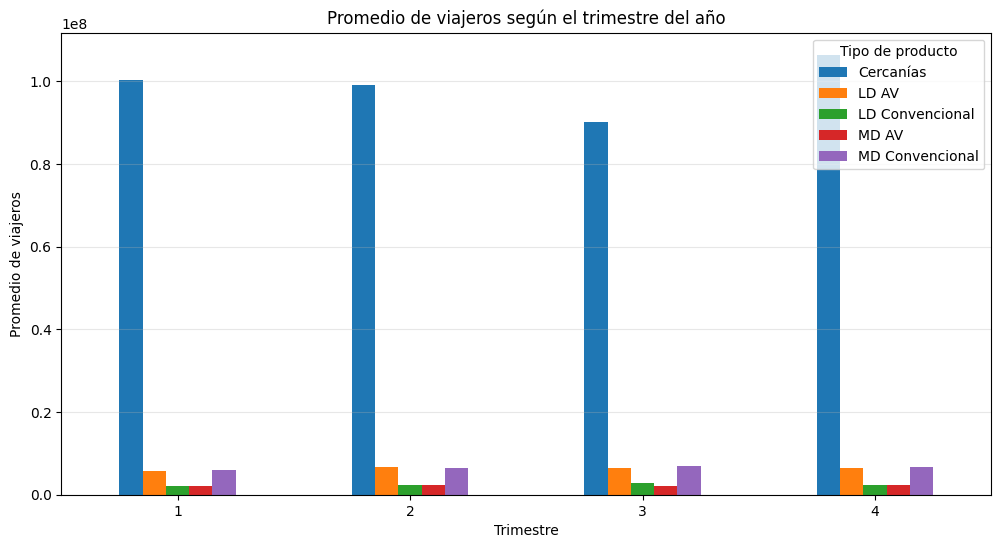

In [52]:
tabla_estacionalidad.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Promedio de viajeros según el trimestre del año")
plt.xlabel("Trimestre")
plt.ylabel("Promedio de viajeros")
plt.xticks(rotation=0)
plt.legend(title="Tipo de producto")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [53]:
# Crear una copia para el análisis estacional
datos_estacionales = viajeros_trimestre.copy()

# Extraer el año
datos_estacionales["Año"] = (
    datos_estacionales["Fecha"].dt.year
)

# Excluir 2026 porque solo tenemos dos trimestres
datos_estacionales = datos_estacionales[
    datos_estacionales["Año"] <= 2025
]

# Calcular la media anual de cada producto
datos_estacionales["Media_anual"] = (
    datos_estacionales.groupby(
        ["Tipo de producto", "Año"]
    )["Viajeros"].transform("mean")
)

# Calcular el índice estacional
datos_estacionales["Indice_estacional"] = (
    datos_estacionales["Viajeros"]
    / datos_estacionales["Media_anual"]
    * 100
)

display(datos_estacionales.head(12))

,Trimestre,Tipo de producto,Viajeros,Fecha,Numero_trimestre,Año,Media_anual,Indice_estacional
0,2016T1,Cercanías,100892888.0,2016-01-01,1,2016,1.022275e+08,98.694497
1,2016T1,LD AV,4717790.0,2016-01-01,1,2016,5.087930e+06,92.725131
2,2016T1,LD Convencional,2572312.0,2016-01-01,1,2016,2.860102e+06,89.937779
3,2016T1,MD AV,1752984.0,2016-01-01,1,2016,1.827289e+06,95.933580
4,2016T1,MD Convencional,5443411.0,2016-01-01,1,2016,5.829646e+06,93.374649
5,2016T2,Cercanías,106825480.0,2016-04-01,2,2016,1.022275e+08,104.497822
6,2016T2,LD AV,5407605.0,2016-04-01,2,2016,5.087930e+06,106.283002
7,2016T2,LD Convencional,2820442.0,2016-04-01,2,2016,2.860102e+06,98.613345
8,2016T2,MD AV,1940205.0,2016-04-01,2,2016,1.827289e+06,106.179413
9,2016T2,MD Convencional,6094877.0,2016-04-01,2,2016,5.829646e+06,104.549702


In [54]:
indice_estacional = datos_estacionales.groupby(
    ["Tipo de producto", "Numero_trimestre"]
)["Indice_estacional"].mean().reset_index()

tabla_indices = indice_estacional.pivot(
    index="Numero_trimestre",
    columns="Tipo de producto",
    values="Indice_estacional"
)

display(tabla_indices.round(1))

Tipo de producto,Cercanías,LD AV,LD Convencional,MD AV,MD Convencional
Numero_trimestre,,,,,
1,103.5,96.7,93.8,102.3,94.1
2,96.7,94.8,93.0,92.8,94.6
3,91.6,105.1,114.9,95.4,107.7
4,108.2,103.3,98.3,109.5,103.6


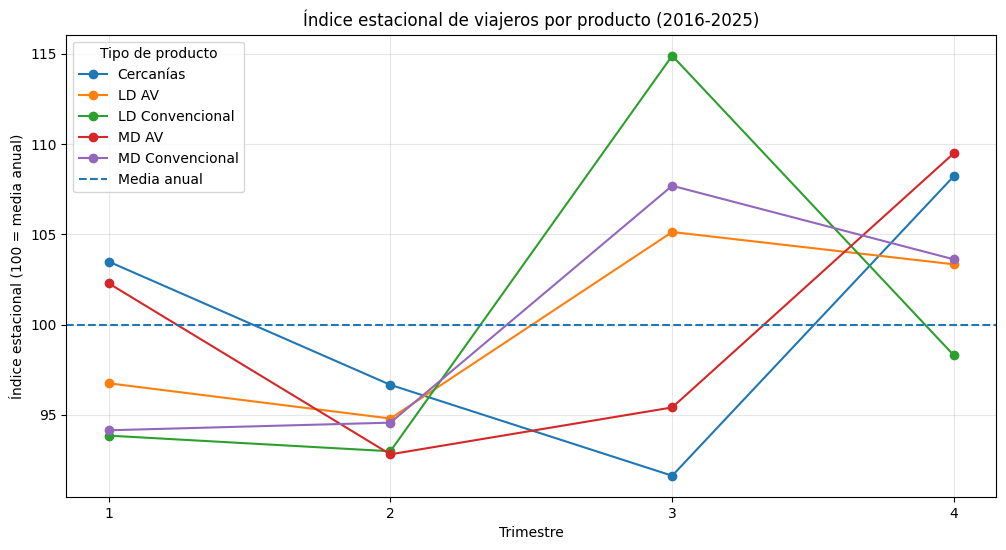

In [55]:
tabla_indices.plot(
    kind="line",
    marker="o",
    figsize=(12, 6)
)

plt.axhline(
    y=100,
    linestyle="--",
    label="Media anual"
)

plt.title("Índice estacional de viajeros por producto (2016-2025)")
plt.xlabel("Trimestre")
plt.ylabel("Índice estacional (100 = media anual)")
plt.xticks([1, 2, 3, 4])
plt.grid(alpha=0.3)
plt.legend(title="Tipo de producto")
plt.show()

In [56]:
# Extraer el año de la fecha
viajeros_trimestre["Año"] = (
    viajeros_trimestre["Fecha"].dt.year
)

# Seleccionar únicamente años completos
datos_anuales = viajeros_trimestre[
    viajeros_trimestre["Año"] <= 2025
].copy()

print("Años incluidos:")
print(sorted(datos_anuales["Año"].unique()))

Años incluidos:
[np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]


In [58]:
# Sumar los viajeros de los cuatro trimestres de cada año
evolucion_anual = datos_anuales.groupby(
    ["Año", "Tipo de producto"]
)["Viajeros"].sum().reset_index()

# Cambiar el nombre de la columna
evolucion_anual = evolucion_anual.rename(
    columns={"Viajeros": "Total_anual"}
)

display(evolucion_anual.head(15))

,Año,Tipo de producto,Total_anual
0,2016,Cercanías,408909881.0
1,2016,LD AV,20351721.0
2,2016,LD Convencional,11440407.0
3,2016,MD AV,7309157.0
4,2016,MD Convencional,23318582.0
5,2017,Cercanías,423649904.0
6,2017,LD AV,21107686.0
7,2017,LD Convencional,11766126.0
8,2017,MD AV,7652855.0
9,2017,MD Convencional,23673912.0


In [59]:
tabla_anual = evolucion_anual.pivot(
    index="Año",
    columns="Tipo de producto",
    values="Total_anual"
)

display(tabla_anual.round(0))

Tipo de producto,Cercanías,LD AV,LD Convencional,MD AV,MD Convencional
Año,,,,,
2016,408909881.0,20351721.0,11440407.0,7309157.0,23318582.0
2017,423649904.0,21107686.0,11766126.0,7652855.0,23673912.0
2018,440583382.0,21332331.0,12273700.0,8653705.0,24214729.0
2019,443178453.0,22372822.0,12145913.0,8877431.0,24256908.0
2020,238775624.0,7602913.0,4282536.0,3418189.0,11329963.0
2021,284090797.0,13488964.0,6532697.0,4526866.0,15411716.0
2022,372925465.0,23721234.0,9501802.0,8564605.0,25873602.0
2023,441995884.0,32412977.0,9536452.0,12607815.0,37814535.0
2024,448112800.0,39648610.0,9226676.0,13276212.0,38812608.0


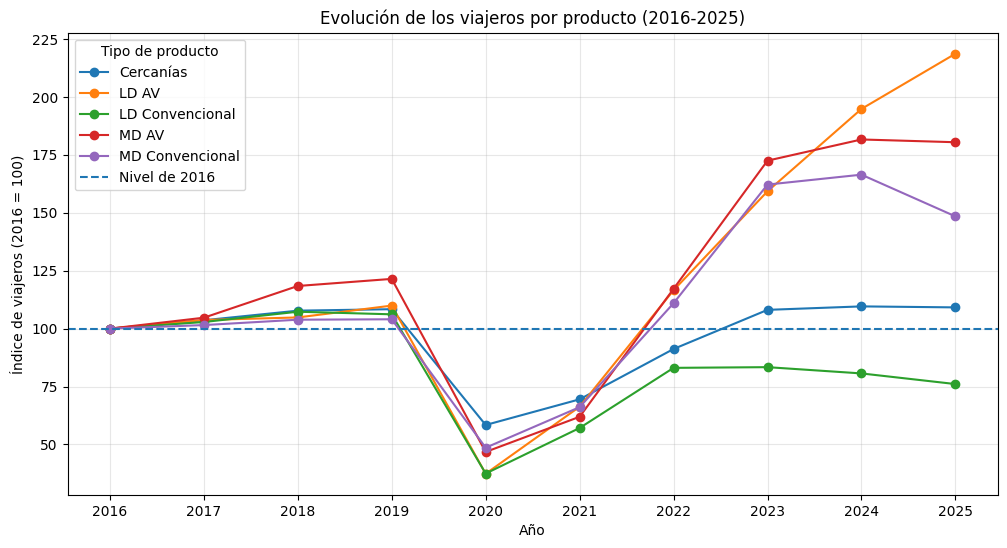

In [60]:
# Calcular la evolución tomando 2016 como base 100
indice_anual = tabla_anual.div(
    tabla_anual.loc[2016]
) * 100

# Dibujar la evolución
indice_anual.plot(
    marker="o",
    figsize=(12, 6)
)

plt.axhline(
    y=100,
    linestyle="--",
    label="Nivel de 2016"
)

plt.title(
    "Evolución de los viajeros por producto (2016-2025)"
)
plt.xlabel("Año")
plt.ylabel("Índice de viajeros (2016 = 100)")
plt.xticks(indice_anual.index)
plt.grid(alpha=0.3)
plt.legend(title="Tipo de producto")
plt.show()

In [61]:
# Calcular la variación porcentual respecto al año anterior
variacion_anual = tabla_anual.pct_change() * 100

# Mostrar los resultados
display(variacion_anual.round(2))

Tipo de producto,Cercanías,LD AV,LD Convencional,MD AV,MD Convencional
Año,,,,,
2016,NaN,NaN,NaN,NaN,NaN
2017,3.60,3.71,2.85,4.70,1.52
2018,4.00,1.06,4.31,13.08,2.28
2019,0.59,4.88,-1.04,2.59,0.17
2020,-46.12,-66.02,-64.74,-61.50,-53.29
2021,18.98,77.42,52.54,32.43,36.03
2022,31.27,75.86,45.45,89.20,67.88
2023,18.52,36.64,0.36,47.21,46.15
2024,1.38,22.32,-3.25,5.30,2.64


In [62]:
# Comparar 2025 con 2019
comparacion_2019_2025 = (
    (tabla_anual.loc[2025] / tabla_anual.loc[2019]) - 1
) * 100

comparacion_2019_2025 = comparacion_2019_2025.rename(
    "Variación 2019-2025 (%)"
)

display(comparacion_2019_2025.round(2))

,Variación 2019-2025 (%)
Tipo de producto,
Cercanías,0.72
LD AV,98.90
LD Convencional,-28.36
MD AV,48.57
MD Convencional,42.71


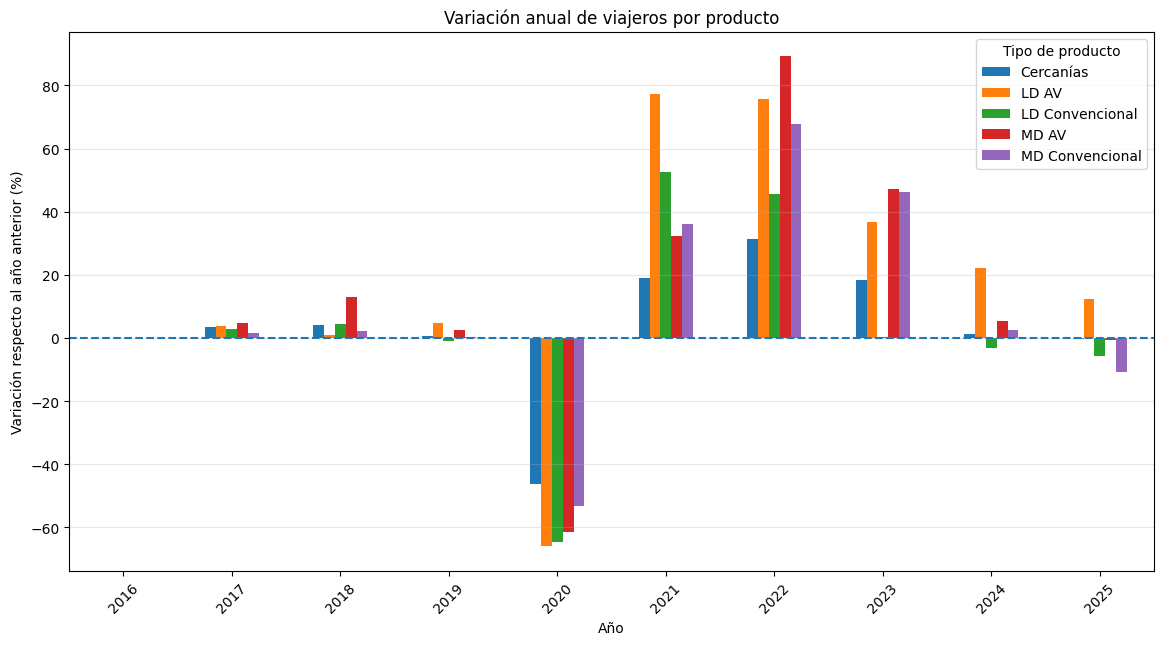

In [64]:
variacion_anual.plot(
    kind="bar",
    figsize=(14, 7)
)

plt.axhline(y=0, linestyle="--")

plt.title("Variación anual de viajeros por producto")
plt.xlabel("Año")
plt.ylabel("Variación respecto al año anterior (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Tipo de producto")
plt.show()

In [65]:
# Comparar el número de viajeros de 2019 y 2025
comparacion = pd.DataFrame({
    "Viajeros_2019": tabla_anual.loc[2019],
    "Viajeros_2025": tabla_anual.loc[2025]
})

# Calcular la diferencia absoluta
comparacion["Diferencia"] = (
    comparacion["Viajeros_2025"]
    - comparacion["Viajeros_2019"]
)

# Calcular la variación porcentual
comparacion["Variacion_%"] = (
    comparacion["Diferencia"]
    / comparacion["Viajeros_2019"]
) * 100

display(comparacion.round(2))

,Viajeros_2019,Viajeros_2025,Diferencia,Variacion_%
Tipo de producto,,,,
Cercanías,443178453.0,446348801.0,3170348.0,0.72
LD AV,22372822.0,44499598.0,22126776.0,98.90
LD Convencional,12145913.0,8701707.0,-3444206.0,-28.36
MD AV,8877431.0,13189297.0,4311866.0,48.57
MD Convencional,24256908.0,34616678.0,10359770.0,42.71


In [66]:
crecimiento_total = (
    (tabla_anual.loc[2025] / tabla_anual.loc[2016]) - 1
) * 100

crecimiento_total = crecimiento_total.sort_values(
    ascending=False
)

display(
    crecimiento_total.round(2).to_frame(
        name="Crecimiento 2016-2025 (%)"
    )
)

,Crecimiento 2016-2025 (%)
Tipo de producto,
LD AV,118.65
MD AV,80.45
MD Convencional,48.45
Cercanías,9.16
LD Convencional,-23.94


In [67]:
# Reunir los dos análisis en una sola tabla
resumen_final = comparacion.copy()

resumen_final["Crecimiento_2016_2025_%"] = crecimiento_total

# Ordenar por crecimiento entre 2019 y 2025
resumen_final = resumen_final.sort_values(
    "Variacion_%",
    ascending=False
)

display(resumen_final.round(2))

,Viajeros_2019,Viajeros_2025,Diferencia,Variacion_%,Crecimiento_2016_2025_%
Tipo de producto,,,,,
LD AV,22372822.0,44499598.0,22126776.0,98.90,118.65
MD AV,8877431.0,13189297.0,4311866.0,48.57,80.45
MD Convencional,24256908.0,34616678.0,10359770.0,42.71,48.45
Cercanías,443178453.0,446348801.0,3170348.0,0.72,9.16
LD Convencional,12145913.0,8701707.0,-3444206.0,-28.36,-23.94
